# Where is the UK's solar pipeline getting stuck?
**Client question:** a mid-size UK solar and battery developer wants to know which regions to prioritise, and where its development budget is most at risk.

This notebook walks through the analysis step by step. The same logic runs end to end in `run_analysis.py`; the recommendation is in `docs/recommendation_memo.md`.

In [1]:
import sys, pandas as pd
sys.path.append('..')
from src.prepare import load
from src import analysis
pd.set_option('display.float_format', '{:,.2f}'.format)

## 1. Load and clean the data
Source: DESNZ Renewable Energy Planning Database (Q2 2026). Scope: solar PV and battery projects of 1 MW or more. The cleaning log records every exclusion so the numbers can be traced.

In [2]:
df, log = load()
log

,step,records
0,Rows in REPD extract,14657
1,Solar PV and battery records,10138
2,Dropped: capacity blank or not a number,1080
3,Dropped: 'Revised' records superseded by a new...,446
4,Dropped: below 1 MW (REPD threshold fell from ...,3725
5,Dropped: offshore or region missing,1
6,Flagged: at least one event date after the ext...,1
7,Flagged: decision dated before submission (dur...,0
8,Final analysis set (projects),4886


## 2. How big is the pipeline, and where does capacity sit?

In [3]:
analysis.pipeline_by_stage(df)

tech,Battery,Solar,Total
stage,,,
In planning,42.20,16.90,59.10
"Consented, not built",72.00,25.80,97.90
Under construction,9.90,3.20,13.10
Operational,5.00,11.10,16.00


Almost 98 GW holds planning consent but has not started construction, about six times the capacity that is operating. That is the first sign the bottleneck sits after planning.

## 3. How fast is demand for consents growing? (GW applied for per year)

In [4]:
analysis.applications_by_year(df)

tech,Battery,Solar
submitted_year,,
2015,0.00,3.70
2016,0.80,0.20
2017,2.50,0.20
2018,1.60,0.60
2019,1.90,1.10
2020,2.40,2.60
2021,8.80,5.80
2022,15.50,7.30
2023,26.60,8.70


Battery applications grew about fivefold between 2021 and 2025. Because REPD's inclusion threshold fell from 1 MW to 150 kW in 2021, the 1 MW floor keeps this series consistent.

## 4. What happens to projects after they are consented?
Projects consented in 2019-22 have had at least three and a half years to start building.

In [5]:
analysis.cohort_outcomes(df)

status_now,Operational,Under construction,"Consented, not built",Expired or abandoned,projects
granted_year,,,,,
2019,0.34,0.17,0.26,0.22,58
2020,0.31,0.27,0.37,0.05,86
2021,0.27,0.20,0.49,0.05,205
2022,0.14,0.18,0.68,0.00,304


## 5. Regional scorecard
Approval rate uses applications submitted 2021-24; build-out uses consents granted 2019-22. Regions with fewer than 20 consents are not ranked.

In [6]:
score = analysis.regional_scorecard(df)
score[['approval_rate', 'build_out_rate', 'build_out_ci_low', 'build_out_ci_high',
       'gw_applied_2021_24', 'consents_2019_22', 'quadrant']]

,approval_rate,build_out_rate,build_out_ci_low,build_out_ci_high,gw_applied_2021_24,consents_2019_22,quadrant
Region,,,,,,,
Eastern,0.95,0.46,0.38,0.55,12.13,95,Go now
Wales,0.93,0.46,0.31,0.62,5.21,26,Selective niche
East Midlands,0.94,0.46,0.35,0.56,16.06,59,Go now
South East,0.92,0.45,0.36,0.55,9.63,75,Go now
West Midlands,0.94,0.43,0.33,0.55,7.18,53,Selective niche
South West,0.92,0.42,0.34,0.51,8.41,92,Deprioritise
North West,0.95,0.42,0.32,0.52,9.31,60,Deprioritise
Scotland,0.93,0.40,0.32,0.48,26.39,95,Crowded: grid-first only
London,0.83,0.33,0.12,0.65,0.21,6,Too few consents to rank


Approval rates sit in a narrow 92-99% band, so they do not separate regions. Build-out does: the North East and Yorkshire are clearly weaker, while the top seven regions overlap within their confidence intervals.

## 6. Time from consent to construction (projects that started)

In [7]:
analysis.time_to_construction(df)

,median,count
tech,,
Battery,19.00,145
Solar,7.60,1035


## 7. Headline numbers used in the memo

In [8]:
pd.Series(analysis.headline_numbers(df)).round(3)

gw_operational                       16.00
gw_under_construction                13.10
gw_consented_not_built               97.90
gw_in_planning                       59.10
approval_rate_2021_24                 0.94
cohort_build_out_rate                 0.41
cohort_size                         653.00
gw_stalled                           11.58
gw_stalled_solar                      4.98
n_stalled                           397.00
battery_share_consented_not_built     0.74
dtype: float64

## 8. Charts
All charts are written to `outputs/figures` by `run_analysis.py`.

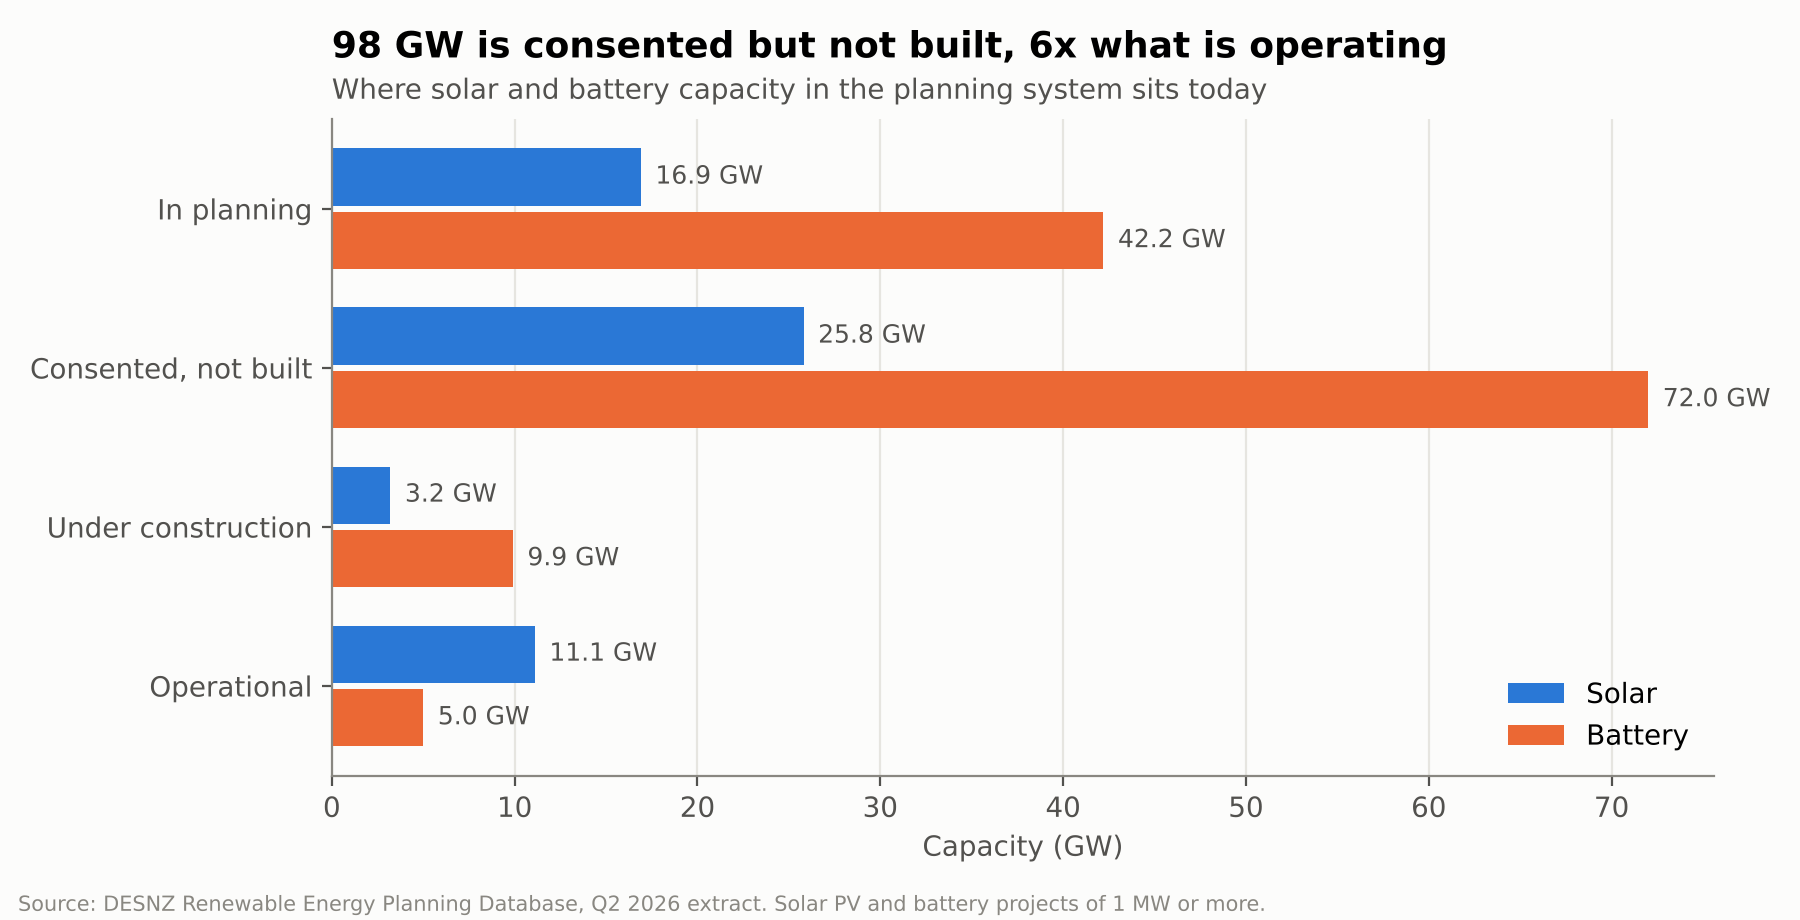

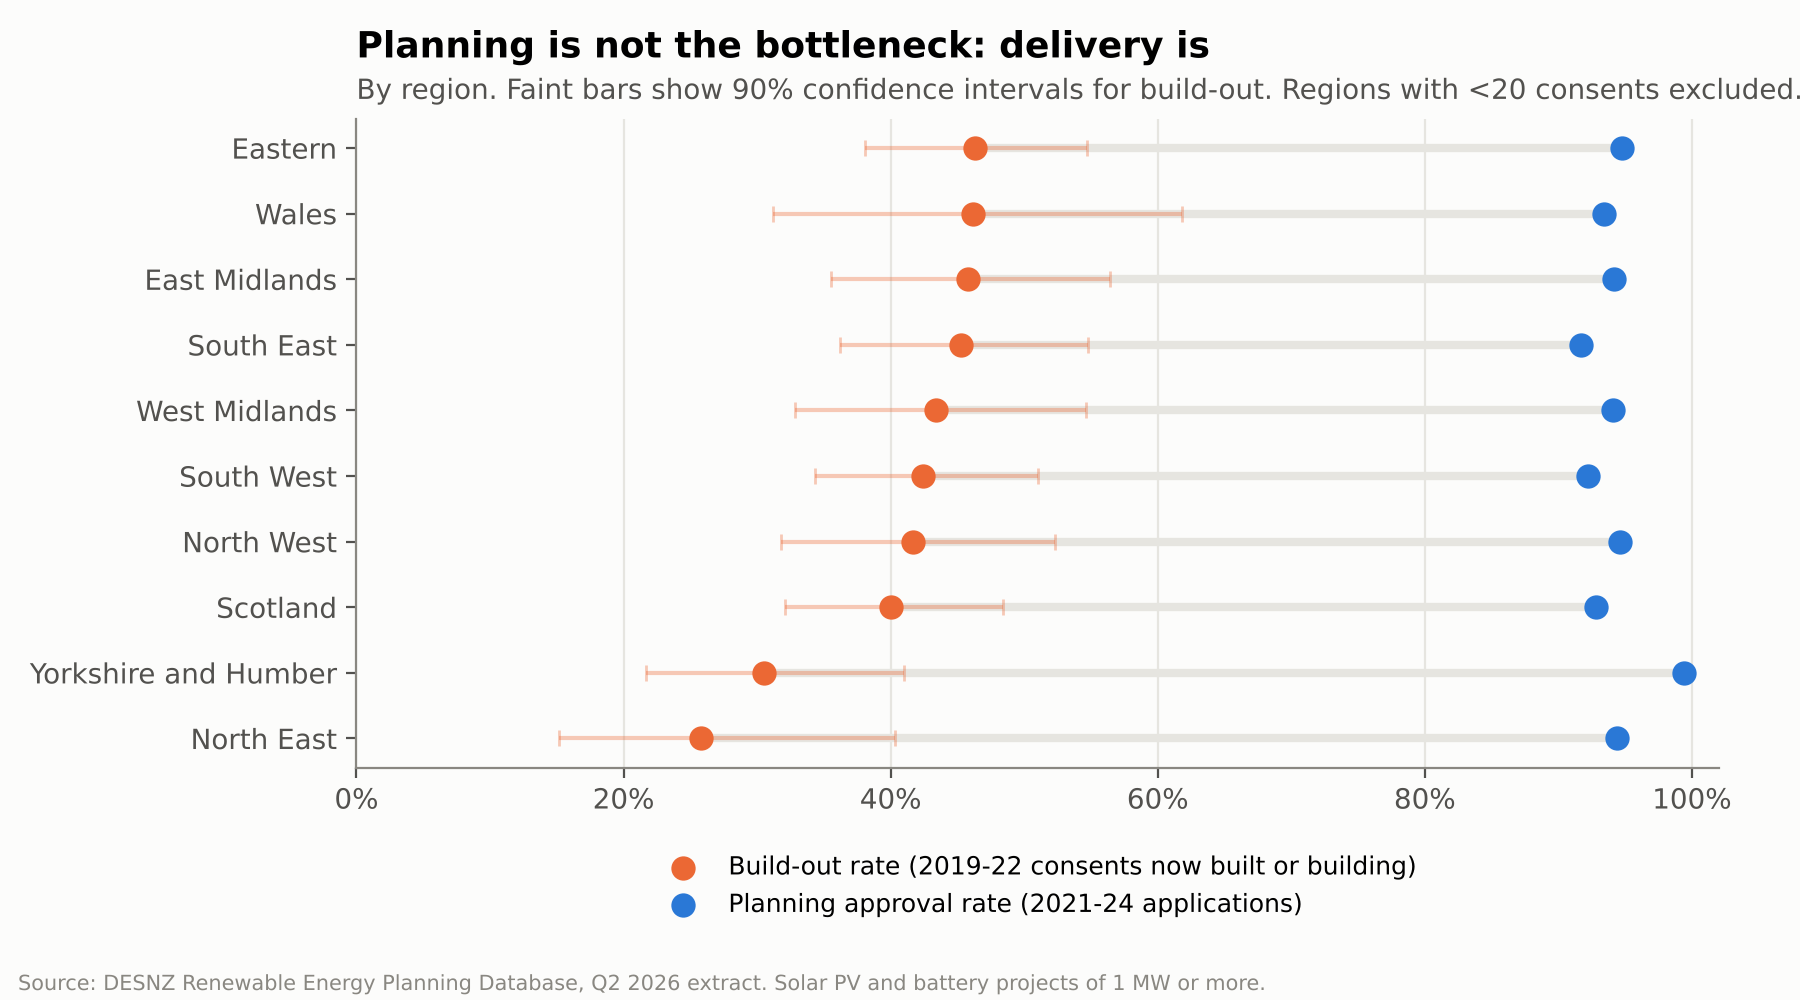

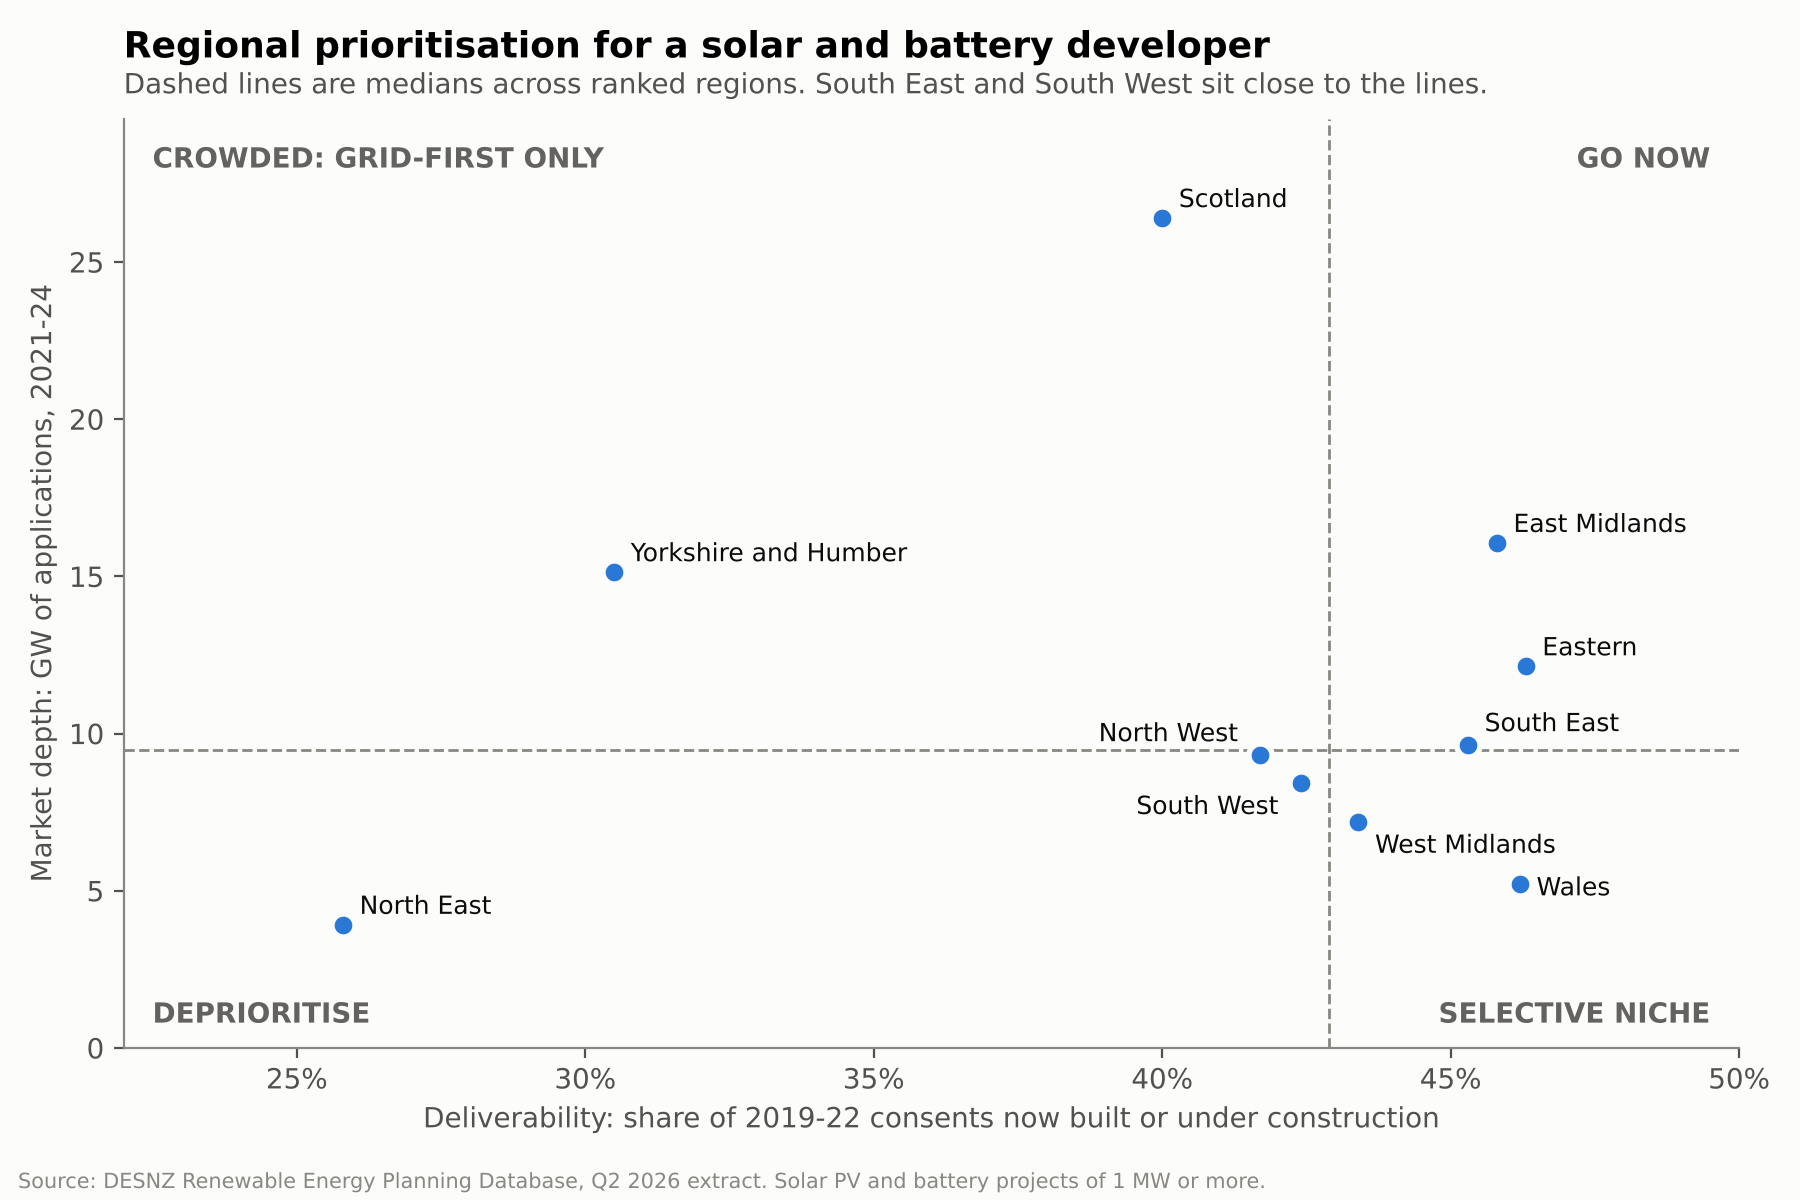

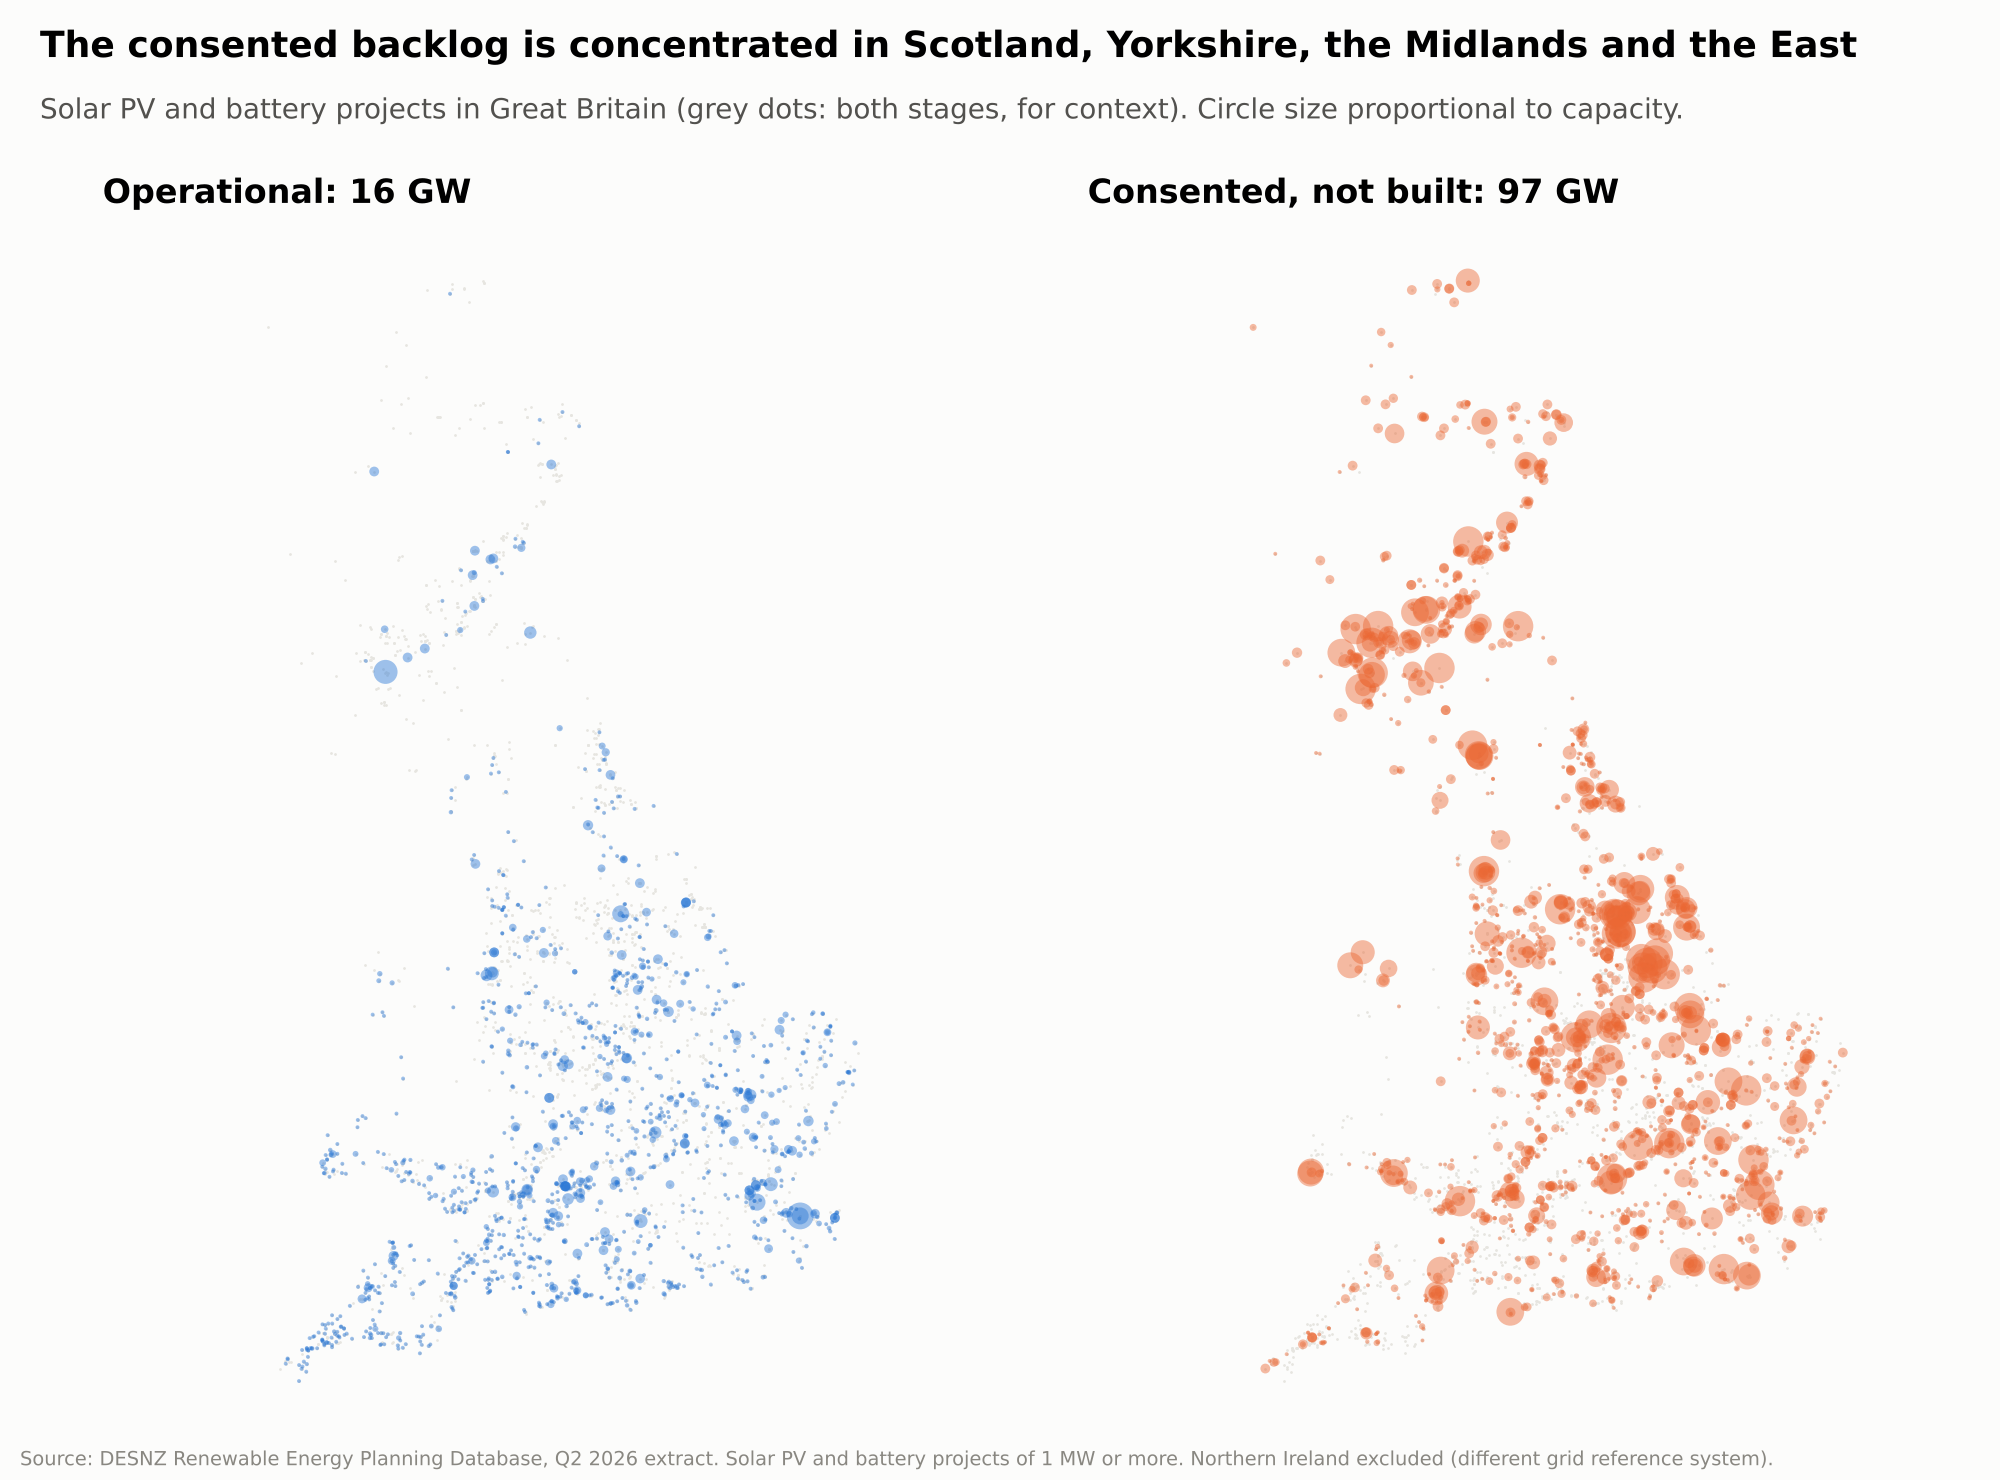

In [9]:
from IPython.display import Image, display
for f in ['01_pipeline_by_stage', '04_approval_vs_buildout', '05_region_matrix', '06_pipeline_map']:
    display(Image(f'../outputs/figures/{f}.png', width=800))